# Exercise 2 — The detectability map

*Covers notebooks 03. Difficulty: ★★☆☆☆*

Every planet is a point in the contrast-separation plane. Map the time to S/N 5 over that plane and read off where the coronagraph's limits lie.

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

### 2.1 — The grid

For a V = 5 host in R3 (raw contrast $10^{-8}$, ppgain 30), compute the time to S/N 5 on a grid of
planet contrast ($10^{-10}$ to $10^{-7}$, 25 steps) and separation (0.05" to 0.9", 25 steps).
Show it as an image with log colour scale (hours), and overlay the contrast floor and the 50 %
throughput IWA.

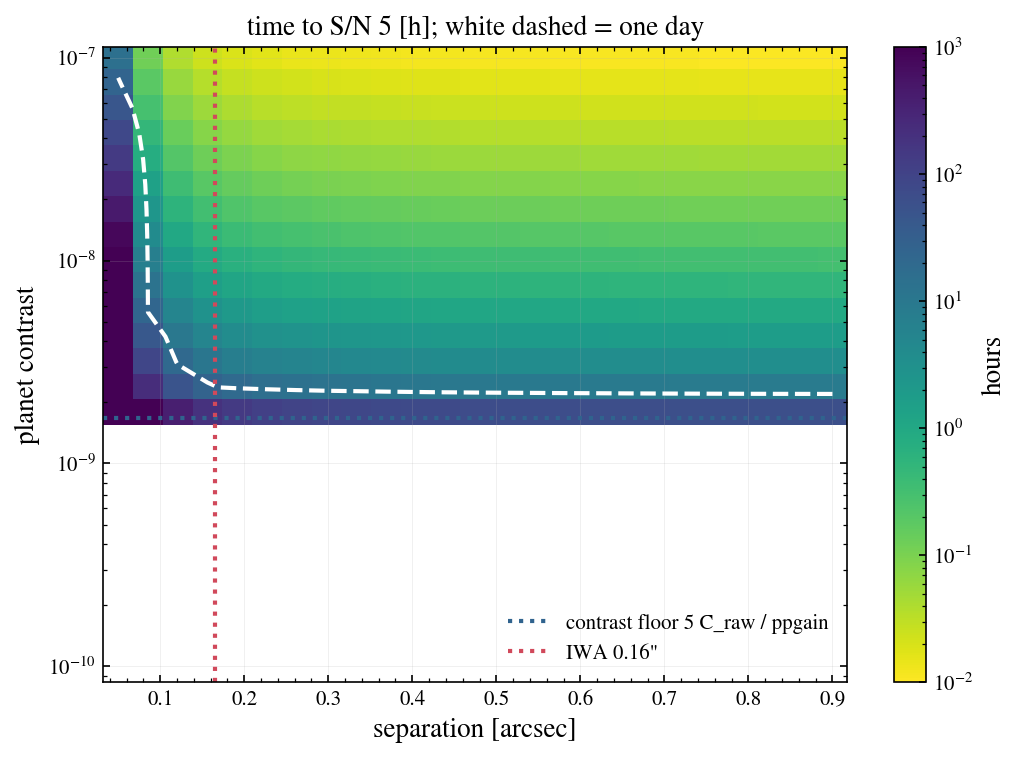

In [2]:
sim = Simulation.from_default(filter="R3", hoststarmag=5.0, hoststar_band="johnson_v", planetdeltamag=20, contrast=1e-8, ppgain=30, separation=0.4)
contrasts = np.logspace(-10, -7, 25); seps = np.linspace(0.05, 0.9, 25)
hours = np.full((contrasts.size, seps.size), np.nan)
for i, c in enumerate(contrasts):
    for j, sp in enumerate(seps):
        sim.update(scene__planet__deltamag=-2.5 * np.log10(c), coronagraph__separation=sp)
        hours[i, j] = hours_to_snr(sim)
sim.reset()
cg = sim.coronagraph
lamD = (cg.primary_filter / cg.diameter_primary).to_value(u.arcsec, equivalencies=u.dimensionless_angles())
IWA = (cg._lamD * lamD)[np.argmax(cg._throughput >= 0.5 * cg._throughput.max())]
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.pcolormesh(seps, contrasts, hours, norm=LogNorm(1e-2, 1e3), cmap="viridis_r", shading="nearest")
ax.contour(seps, contrasts, np.nan_to_num(hours, nan=1e9), levels=[24], colors="w", linestyles="--")
ax.axhline(5e-8 / 30, color="C3", ls=":", label="contrast floor 5 C_raw / ppgain")
ax.axvline(IWA, color="C1", ls=":", label=f"IWA {IWA:.2f}\"")
ax.set(yscale="log", xlabel="separation [arcsec]", ylabel="planet contrast", title="time to S/N 5 [h]; white dashed = one day")
fig.colorbar(im, ax=ax, label="hours"); ax.legend(loc="lower right")
plt.show()

> ✏️ **Before you run the next cell:** where on the grid is an Earth twin (contrast 1e-10 at 0.1" for a Sun at 10 pc)? Reachable, or NaN? Write your guess down (or put it in the room poll), then run.

### 2.2 — Reading the map

Which separation gives the shortest time at contrast $10^{-8}$, and why does the time go *up* again
beyond a few tenths of an arcsecond, if at all? Is an Earth twin ($10^{-10}$ at 0.1") anywhere on
the map?

In [3]:
i = np.argmin(np.abs(contrasts - 1e-8))
print(f"contrast 1e-8: fastest at {seps[np.nanargmin(hours[i])]:.2f}\" ({np.nanmin(hours[i]):.2f} h); at 0.9\": {hours[i, -1]:.2f} h")
# The mask throughput saturates beyond ~0.5", so the time flattens rather than rises: zodi/exozodi are negligible here.
print(f"Earth twin, 1e-10 at 0.1\": {hours[0, np.argmin(np.abs(seps - 0.1))]} (NaN = below the floor of {5e-8 / 30:.1e})")

contrast 1e-8: fastest at 0.90" (0.32 h); at 0.9": 0.32 h
Earth twin, 1e-10 at 0.1": nan (NaN = below the floor of 1.7e-09)


### 2.3 — What would it take?

Does any combination of raw contrast ($10^{-8}$, $10^{-9}$, $10^{-10}$) and ppgain (30, 100, 300)
put a $10^{-10}$ planet at 0.1" within one day for this host? If not, what is the limit once the
speckle floor is out of the way?

In [4]:
sim.update(scene__planet__deltamag=25.0, coronagraph__separation=0.1)
print(f"{'raw':>7} " + "".join(f"{f'ppgain {g}':>12}" for g in (30, 100, 300)))
for raw in (1e-8, 1e-9, 1e-10):
    row = []
    for g in (30, 100, 300):
        sim.update(coronagraph__raw_dh_contrast=raw, coronagraph__ppgain=g)
        row.append(hours_to_snr(sim))
    print(f"{raw:7.0e} " + "".join(f"{h:12.1f}" for h in row) + "   hours")
sim.reset()
# None: once the floor is cleared the time hardly moves with ppgain or raw contrast. At 0.1" the mask
# transmits 17 % and a 1e-10 planet gives ~1e-3 e-/s: photon noise from zodi, dark and read noise set
# a limit of thousands of hours. Earths need a brighter (closer) host, a larger separation, or a bigger telescope.

    raw    ppgain 30  ppgain 100  ppgain 300


  1e-08          nan         nan         nan   hours


  1e-09          nan     28631.7     22087.3   hours


  1e-10      21776.3     21224.4     21177.3   hours


> 🤖 **Ask Jupyter AI:** *Re-draw the map for raw contrast 1e-9 and overlay the known RV giants from lazuli/esc/tutorial/data/12_nearby_rv_giants.csv (exercise 4 computes their contrast and separation).*
>
> Ask it to colour the points by host V magnitude, since the grid is for V = 5 only.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/esc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*